In [1]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

df = pd.read_csv("../data/cleaned_cars.csv")
X = df.drop(columns="price")
y = np.log1p(df["price"])         

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

num = ["engine_cc", "mileage"]
cat = [c for c in X.columns if c not in num]

pre = ColumnTransformer([
    ("num", StandardScaler(), num),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat),
])

baseline = Pipeline([("pre", pre), ("model", LinearRegression())])
baseline.fit(X_train, y_train)

pred = baseline.predict(X_test)
print("R² (log scale):", r2_score(y_test, pred))
print("MAE (PKR):", mean_absolute_error(np.expm1(y_test), np.expm1(pred)))

R² (log scale): 0.805477339145175
MAE (PKR): 773057.6909272759


In [2]:
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder


pre_tree = ColumnTransformer([
    ("num", "passthrough", num),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat),
])

models = {
    "Linear Regression": baseline,
    "Random Forest": Pipeline([("pre", pre_tree),
        ("model", RandomForestRegressor(n_estimators=150, min_samples_leaf=2,
                                        n_jobs=-1, random_state=42))]),
    "Gradient Boosting": Pipeline([("pre", pre_tree),
        ("model", HistGradientBoostingRegressor(max_iter=300, random_state=42))]),
}

rows = []
for name, m in models.items():
    cv = cross_validate(m, X_train, y_train, cv=3,
                        scoring=("r2", "neg_mean_absolute_error"))
    rows.append({"model": name,
                 "CV R²": cv["test_r2"].mean(),
                 "CV MAE (log)": -cv["test_neg_mean_absolute_error"].mean()})

results = pd.DataFrame(rows).round(4)
results

,model,CV R²,CV MAE (log)
0,Linear Regression,0.8027,0.2610
1,Random Forest,0.8605,0.1933
2,Gradient Boosting,0.8695,0.1975


In [3]:
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np
import pandas as pd

In [4]:
best = models["Gradient Boosting"]

best.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


In [5]:
pred = np.expm1(best.predict(X_test))
actual = np.expm1(y_test)

In [6]:
print("R² Score:", r2_score(y_test, best.predict(X_test)))

print("MAE (PKR):", mean_absolute_error(actual, pred))

median_error = ((pred - actual).abs() / actual).median()

print("Median % Error:", median_error*100)

R² Score: 0.8772004702708908
MAE (PKR): 552739.0831293876
Median % Error: 12.921077330944538


In [7]:
err = pd.DataFrame({
    "actual": actual,
    "pred": pred,
    "make": X_test["make"]
})

err["abs_pct"] = (
    abs(err.pred - err.actual) / err.actual
)

In [8]:
err.head()

,actual,pred,make,abs_pct
26632,10900000.0,1.235993e+07,Toyota,0.133938
16113,6345000.0,5.375443e+06,Honda,0.152806
65904,2960000.0,3.202122e+06,Suzuki,0.081798
38651,7979000.0,7.446604e+06,Honda,0.066725
4420,16500000.0,1.568592e+07,Toyota,0.049338


In [9]:
err["price_band"] = pd.qcut(
    err.actual,
    5
)

price_error = (
    err.groupby(
        "price_band",
        observed=True
    )["abs_pct"]
    .median()
)

price_error

price_band
(329999.999, 1270000.0]    0.209234
(1270000.0, 2250000.0]     0.155098
(2250000.0, 3348000.0]     0.119969
(3348000.0, 4990000.0]     0.113680
(4990000.0, 20500000.0]    0.084567
Name: abs_pct, dtype: float64

In [10]:
top = X_test["make"].value_counts().head(5).index

make_error = (
    err[err.make.isin(top)]
    .groupby("make")["abs_pct"]
    .median()
)

make_error

make
Daihatsu    0.130892
Honda       0.135814
KIA         0.068629
Suzuki      0.136336
Toyota      0.128039
Name: abs_pct, dtype: float64

In [11]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

In [12]:
sample = X_test.sample(
    min(5000,len(X_test)),
    random_state=42
)

r = permutation_importance(
    best,
    sample,
    y_test.loc[sample.index],
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
    scoring="r2"
)


imp = pd.Series(
    r.importances_mean,
    index=sample.columns
).sort_values()


imp

ad_city         0.002965
fuel_type       0.010095
assembly        0.011626
color           0.023052
registered      0.034861
body            0.047529
make            0.105950
model           0.122262
mileage         0.142763
transmission    0.220198
engine_cc       0.418946
dtype: float64

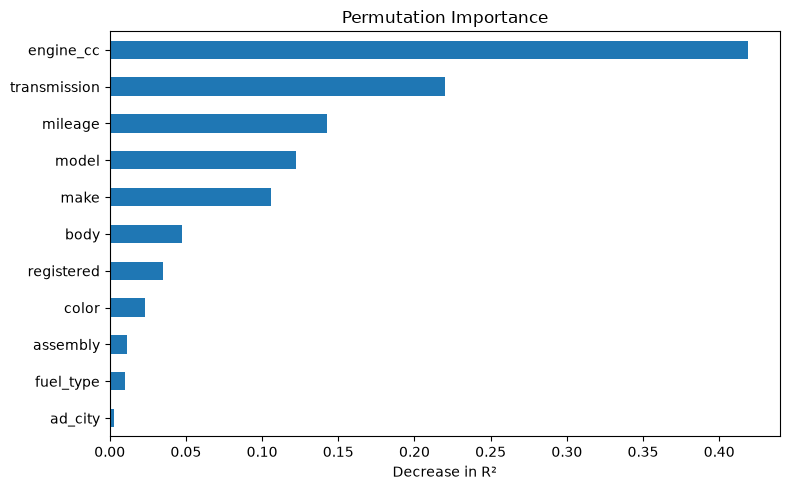

In [13]:
imp.plot.barh(figsize=(8,5))

plt.title(
    "Permutation Importance"
)

plt.xlabel(
    "Decrease in R²"
)

plt.tight_layout()

plt.savefig(
    "../reports/feature_importance.png",
    dpi=150
)

plt.show()

In [14]:
import joblib
import os

In [15]:
os.makedirs("../app", exist_ok=True)

In [16]:
joblib.dump(
    best,
    "../app/model.joblib",
    compress=3
)

['../app/model.joblib']

In [17]:
size = os.path.getsize(
    "../app/model.joblib"
)

print(
    size/1e6,
    "MB"
)

0.458233 MB


In [18]:
import json

cat_cols = [
    "assembly", "body", "ad_city", "color", "fuel_type",
    "make", "model", "registered", "transmission"
]

options = {
    c: sorted(df[c].dropna().unique().tolist())
    for c in cat_cols
}

options["models_by_make"] = (
    df.groupby("make")["model"]
    .apply(lambda s: sorted(s.unique().tolist()))
    .to_dict()
)

with open("../app/options.json", "w") as f:
    json.dump(options, f)

print("options.json created successfully")

options.json created successfully


In [20]:
globals().keys()

dict_keys(['__name__', '__doc__', '__package__', '__loader__', '__spec__', '__builtin__', '__builtins__', '_ih', '_oh', '_dh', 'In', 'Out', 'get_ipython', 'exit', 'quit', 'open', '_', '__', '___', '__session__', '_i', '_ii', '_iii', '_i1', 'np', 'pd', 'train_test_split', 'ColumnTransformer', 'OneHotEncoder', 'StandardScaler', 'Pipeline', 'LinearRegression', 'mean_absolute_error', 'r2_score', 'df', 'X', 'y', 'X_train', 'X_test', 'y_train', 'y_test', 'num', 'cat', 'pre', 'baseline', 'pred', 'json', 'getpass', 'hashlib', 'import_pandas_safely', '__pandas', 'is_data_frame', 'dataframe_columns', 'dtypes_str', 'dataframe_hash', 'get_dataframes', '_1', '_i2', 'cross_validate', 'RandomForestRegressor', 'HistGradientBoostingRegressor', 'OrdinalEncoder', 'pre_tree', 'models', 'rows', 'name', 'm', 'cv', 'results', '_2', '_i3', '_3', '_i4', 'best', '_4', '_i5', 'actual', '_5', '_i6', 'median_error', '_6', '_i7', 'err', '_7', '_i8', '_8', '_i9', 'price_error', '_9', '_i10', 'top', 'make_error', '_1

In [21]:
type(best)

sklearn.pipeline.Pipeline

In [22]:
import joblib

joblib.dump(best, "../app/model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [23]:
best.feature_names_in_

array(['assembly', 'body', 'ad_city', 'color', 'engine_cc', 'fuel_type',
       'make', 'mileage', 'model', 'registered', 'transmission'],
      dtype=object)

In [24]:
best.predict(X_test.head())

array([16.32997014, 15.49735178, 14.97932457, 15.82326874, 16.56827416])